# Tsinghua University - Deep Learning Course <br> Assignment 1(a) Logistic Regression


## 1. Load Dataset


In [1]:
import os
import pathlib
import tqdm #为循环和长时间运行的任务快速、方便地添加一个进度条，还会智能地提供当前处理速度和预估的剩余时间等信息
import numpy as np
import pickle
import zipfile
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Read from dataset file

with zipfile.ZipFile('data/cifar-10-python.zip', 'r') as z:
    def pickle_load_from_zip_entry(name):
        with z.open(name) as f:
            return pickle.load(f, encoding='latin1')

    label_names = pickle_load_from_zip_entry('cifar-10-batches-py/batches.meta')['label_names']
    print('label_names:', label_names)

    print('\nLoading train set ...')
    train_data_dicts = [
        pickle_load_from_zip_entry(f'cifar-10-batches-py/{filename}')
        for filename in ('data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5',)]
    train_data = np.concatenate([d['data'].astype(np.float32) for d in train_data_dicts]) / 255.
    train_labels = np.concatenate([d['labels'] for d in train_data_dicts]) #  5个批次合并成一个训练集
    print(f'train_data: <np.array of shape: {train_data.shape} dtype: {train_data.dtype}>')
    print(f'train_labels: <np.array of shape: {train_labels.shape} dtype: {train_labels.dtype}>')

    print('\nLoading test set ...')
    test_data_dict = pickle_load_from_zip_entry('cifar-10-batches-py/test_batch')
    test_data = test_data_dict['data'].astype(np.float32) / 255.
    test_labels = np.array(test_data_dict['labels'])
    print(f'test_data: <np.array of shape: {test_data.shape} dtype: {test_data.dtype}>')
    print(f'test_labels: <np.array of shape: {test_labels.shape} dtype: {test_labels.dtype}>')


label_names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Loading train set ...


/var/folders/bl/kmvwq1ts1t96gqqcg2x9rhyr0000gn/T/ipykernel_2074/1419769585.py:6: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding='latin1')


train_data: <np.array of shape: (50000, 3072) dtype: float32>
train_labels: <np.array of shape: (50000,) dtype: int64>

Loading test set ...
test_data: <np.array of shape: (10000, 3072) dtype: float32>
test_labels: <np.array of shape: (10000,) dtype: int64>


In [3]:
# Preview dataset

_ = plt.figure(figsize=(10, 10))
_ = plt.title('CIFAR-10 Preview')
for label_index, label_name in enumerate(label_names):
    for img_index, img_data in enumerate(test_data[test_labels == label_index][:10]):
        _ = plt.imshow(
            np.moveaxis(np.reshape(img_data, (3, 32, 32)), 0, 2),
            interpolation='nearest', extent=(img_index, img_index + 1, label_index, label_index + 1))
_ = plt.xticks([])
_ = plt.yticks(np.arange(len(label_names)) + 0.5, label_names)
_ = plt.xlim(0, 10)
_ = plt.ylim(0, len(label_names))

<Figure size 1000x1000 with 1 Axes>

In [4]:
# Keep only 2 categories and remove all others from both image data and labels

active_label_indices = [0, 1]

print('\nTaking subset of label names ...')
active_label_names = [label_names[label_index] for label_index in active_label_indices]
print('active_label_names:', active_label_names)

print('\nTaking subset of train set ...')
train_data = train_data[np.any(train_labels[:, None] == active_label_indices, axis=-1)]
train_labels = train_labels[np.any(train_labels[:, None] == active_label_indices, axis=-1)]
print(f'train_data: <np.array of shape: {train_data.shape} dtype: {train_data.dtype}>')
print(f'train_labels: <np.array of shape: {train_labels.shape} dtype: {train_labels.dtype}>')

print('\nTaking subset of test set ...')
test_data = test_data[np.any(test_labels[:, None] == active_label_indices, axis=-1)]
test_labels = test_labels[np.any(test_labels[:, None] == active_label_indices, axis=-1)]
print(f'test_data: <np.array of shape: {test_data.shape} dtype: {test_data.dtype}>')
print(f'test_labels: <np.array of shape: {test_labels.shape} dtype: {test_labels.dtype}>')



Taking subset of label names ...
active_label_names: ['airplane', 'automobile']

Taking subset of train set ...
train_data: <np.array of shape: (10000, 3072) dtype: float32>
train_labels: <np.array of shape: (10000,) dtype: int64>

Taking subset of test set ...
test_data: <np.array of shape: (2000, 3072) dtype: float32>
test_labels: <np.array of shape: (2000,) dtype: int64>


## 2. Training

In [5]:
# Note on Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
batch_size = 100
max_epoch = 10
lr = 0.001      # learning rate
momentum = 0.9  # momentum
lambd = 0.001   # 正则化系数
eps = 1e-12     # 防止 log(0)
np.random.seed(42)   # 固定种子

# Note on Initialize, Parameters. Refer to the archived source for the detailed original comment.
D = train_data.shape[1] 
W = np.random.randn(D) * 0.001       # weight，初始足够小
b = 0.                               # bias

# 动量变量
v_W = np.zeros_like(W)
v_b = 0.

# 记录
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# 辅助函数
def sigmoid(u):
    u = np.clip(u, -500, 500) # 防止溢出
    return 1 / (1 + np.exp(-u))

def binary_cross_entropy_loss(y_pred, y_true, eps):
    y_pred = np.clip(y_pred, eps, 1 - eps) # 为避免 log(0)，对概率进行裁剪
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

for epoch in range(max_epoch):
    # Note on Training, Data. Refer to the archived source for the detailed original comment.
    perm = np.random.permutation(len(train_data))
    X_shuffled = train_data[perm]        
    y_shuffled = train_labels[perm]
        
    steps_per_epoch = np.ceil(len(train_data) / batch_size).astype(int)
    progress_bar = tqdm.tqdm(range(steps_per_epoch))

    epoch_losses = []
    epoch_accuracies = []
    for step_index in progress_bar:
        # fetch next batch of training data
        X = X_shuffled[step_index * batch_size:(step_index + 1) * batch_size]           # train_data as x (shape: [batch_size, 3072])
        y_true = y_shuffled[step_index * batch_size:(step_index + 1) * batch_size]    # train_labels as y (shape: [batch_size,])
        y_true = (y_true != active_label_indices[0]).astype(int)                        # make binary
        current_batch_size = len(X)
        
        # TODO: forward with sigmoid
        z = X @ W + b
        y_pred = sigmoid(z)       # h_k(x) in the slides

        # TODO: calculate cross-entropy loss & accuracy
        loss = binary_cross_entropy_loss(y_pred, y_true, eps)

        # Note on Accuracy. Refer to the archived source for the detailed original comment.
        # Note on Model, Output, Samples. Refer to the archived source for the detailed original comment.
        probs = np.stack([1 - y_pred, y_pred], axis=1) # (batch_size, 2)
        pred_labels = np.argmax(probs, axis=1)         # (batch_size, )
        accuracy = np.mean(pred_labels == y_true)

        epoch_losses.append(loss)
        epoch_accuracies.append(accuracy)
        progress_bar.set_description(f'loss {loss:.3f} acc {accuracy:.3f}')

        # TODO: update weights
        # Note on Gradient. Refer to the archived source for the detailed original comment.
        error = y_pred - y_true
        grad_W = (X.T @ error)/current_batch_size + lambd * W
        grad_b = np.mean(error)  
        
        # momentum
        v_W = momentum * v_W + lr * grad_W
        W -= v_W
        v_b = momentum * v_b + lr * grad_b
        b -= v_b

    train_losses.append(np.mean(epoch_losses))
    train_accuracies.append(np.mean(epoch_accuracies))

    # test accuracies
    x_test = test_data
    y_true_test = test_labels
    y_true_test = (y_true_test != active_label_indices[0]).astype(int)    # make binary

    # TODO: test set: forward with sigmoid
    z_test = x_test @ W + b
    y_pred_test = sigmoid(z_test)       # h_k(x) in the slides

    # TODO: test set: calculate cross-entropy loss & accuracy
    test_loss = binary_cross_entropy_loss(y_pred_test, y_true_test, eps)
    probs_test = np.stack([1 - y_pred_test, y_pred_test], axis=1)
    test_accuracy = np.mean(np.argmax(probs_test, axis=1) == y_true_test)

    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)
    print(f'  - test acc: {test_accuracy:.3f}')

loss 0.503 acc 0.780: 100%|█████████████████| 100/100 [00:00<00:00, 1221.66it/s]


  - test acc: 0.780


loss 0.415 acc 0.830: 100%|█████████████████| 100/100 [00:00<00:00, 1499.34it/s]


  - test acc: 0.780


loss 0.441 acc 0.780: 100%|█████████████████| 100/100 [00:00<00:00, 1344.66it/s]


  - test acc: 0.796


... (10 outputs left out)

loss 0.368 acc 0.840: 100%|█████████████████| 100/100 [00:00<00:00, 1493.94it/s]


  - test acc: 0.814


loss 0.434 acc 0.820: 100%|█████████████████| 100/100 [00:00<00:00, 1109.21it/s]


  - test acc: 0.814


In [9]:
train_accuracies

[np.float64(0.6980000000000001),
 np.float64(0.7675),
 np.float64(0.7795000000000001),
 np.float64(0.7844),
 np.float64(0.7925),
 np.float64(0.7922),
 np.float64(0.7959),
 np.float64(0.7967),
 np.float64(0.7996000000000001),
 np.float64(0.8036)]

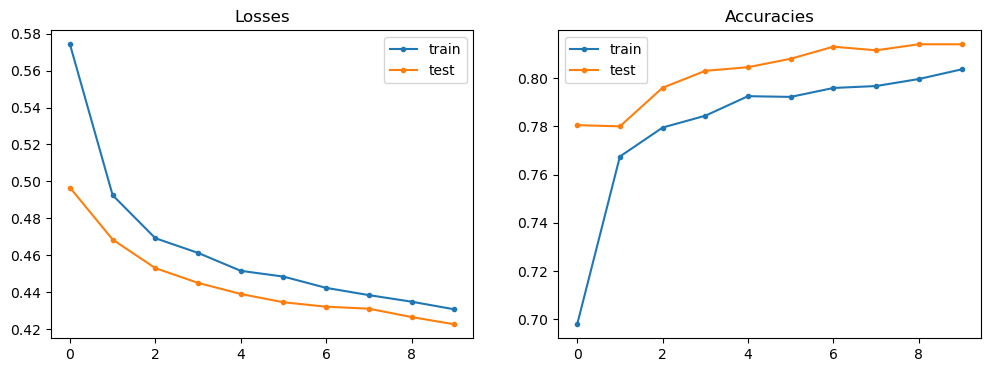

In [6]:
# plot loss & accuracy curve
fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))
a0.set_title('Losses')
a0.plot(train_losses, marker='.', label='train')
a0.plot(test_losses, marker='.', label='test')
a0.legend()
a1.set_title('Accuracies')
a1.plot(train_accuracies, marker='.', label='train')
a1.plot(test_accuracies, marker='.', label='test')
a1.legend()
plt.show()

### Results and Analysis / Results / Analysis

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Experiment Notes

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [10]:
np.random.seed(42)   # 固定种子

# General Function
def train_logistic(train_data, train_labels, test_data, test_labels, 
                  use_bias=True, use_momentum=True, max_epoch=10, batch_size=100, 
                  lr=0.001, momentum=0.9, lambd=0.001, eps=1e-12):

    # 辅助函数
    def sigmoid(u):
        u = np.clip(u, -500, 500) 
        return 1 / (1 + np.exp(-u))
    
    def binary_cross_entropy_loss(y_pred, y_true, eps):
        y_pred = np.clip(y_pred, eps, 1 - eps) 
        return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    
    # Note on Initialize. Refer to the archived source for the detailed original comment.
    D = train_data.shape[1]
    W = np.random.randn(D) * 0.001
    b = 0.0
    
    v_W = np.zeros_like(W)
    v_b = 0.0
    
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    
    for epoch in range(max_epoch):
        # Note on Training, Data. Refer to the archived source for the detailed original comment.
        perm = np.random.permutation(len(train_data))
        X_shuffled = train_data[perm]        
        y_shuffled = train_labels[perm]
        
        steps_per_epoch = int(np.ceil(len(train_data) / batch_size))
        progress_bar = tqdm.tqdm(range(steps_per_epoch), desc=f'Epoch {epoch+1}/{max_epoch}')

        epoch_losses = []
        epoch_accs = []
        
        for step_index in progress_bar:
            # fetch next batch of training data
            start = step_index * batch_size
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]
            current_batch_size = len(X_batch)
            
            # 前向
            logits = X_batch @ W + b
            y_pred = sigmoid(logits)   
            
            # Note on Accuracy. Refer to the archived source for the detailed original comment.
            loss = binary_cross_entropy_loss(y_pred, y_batch, eps)

            probs = np.stack([1 - y_pred, y_pred], axis=1)   # (batch_size, 2)
            pred_labels = np.argmax(probs, axis=1)           # (batch_size,)
            accuracy = np.mean(pred_labels == y_batch)

            epoch_losses.append(loss)
            epoch_accs.append(accuracy)
            progress_bar.set_description(f'loss {loss:.3f} acc {accuracy:.3f}')
        
            # Note on Gradient. Refer to the archived source for the detailed original comment.
            error = y_pred - y_batch
            grad_W = (X_batch.T @ error)/current_batch_size + lambd * W
            grad_b = np.mean(error)
            
            if not use_bias:
                grad_b = 0.0
                
            # 更新
            if use_momentum:
                v_W = momentum * v_W + lr * grad_W
                W -= v_W
                v_b = momentum * v_b + lr * grad_b
                b -= v_b
            else:
                W -= lr * grad_W
                b -= lr * grad_b
                
        # Note on Accuracy. Refer to the archived source for the detailed original comment.
        train_losses.append(np.mean(epoch_losses)) 
        train_accs.append(np.mean(epoch_accs))  

        # test evaluation
        logits_test = test_data @ W + b
        y_pred_test = sigmoid(logits_test)

        test_loss = binary_cross_entropy_loss(y_pred_test, test_labels, eps)

        probs_test = np.stack([1 - y_pred_test, y_pred_test], axis=1)
        test_pred_labels = np.argmax(probs_test, axis=1)
        test_accuracy = np.mean(test_pred_labels == test_labels)

        test_losses.append(test_loss)
        test_accs.append(test_accuracy)

        print(f'  - test acc: {test_accuracy:.3f}')
    
    return train_losses, test_losses, train_accs, test_accs

## 2. Bias or not

In [31]:
train_losses, test_losses, train_accuracies, test_accuracies = train_logistic(
    train_data, train_labels, test_data, test_labels,
    use_bias=True
)

loss 0.503 acc 0.780: 100%|█████████████████| 100/100 [00:00<00:00, 1158.45it/s]


  - test acc: 0.780


loss 0.415 acc 0.830: 100%|█████████████████| 100/100 [00:00<00:00, 1415.07it/s]


  - test acc: 0.780


loss 0.441 acc 0.780: 100%|██████████████████| 100/100 [00:00<00:00, 987.87it/s]


  - test acc: 0.796


... (10 outputs left out)

loss 0.368 acc 0.840: 100%|█████████████████| 100/100 [00:00<00:00, 1412.05it/s]


  - test acc: 0.814


loss 0.434 acc 0.820: 100%|█████████████████| 100/100 [00:00<00:00, 1509.20it/s]


  - test acc: 0.814


In [11]:
train_losses_nobias, test_losses_nobias, train_accuracies_nobias, test_accuracies_nobias = train_logistic(
    train_data, train_labels, test_data, test_labels,
    use_bias=False
)

loss 0.504 acc 0.780: 100%|█████████████████| 100/100 [00:00<00:00, 1204.98it/s]


  - test acc: 0.779


loss 0.416 acc 0.810: 100%|█████████████████| 100/100 [00:00<00:00, 1358.64it/s]


  - test acc: 0.777


loss 0.442 acc 0.780: 100%|█████████████████| 100/100 [00:00<00:00, 1372.48it/s]


  - test acc: 0.794


... (10 outputs left out)

loss 0.369 acc 0.840: 100%|█████████████████| 100/100 [00:00<00:00, 1424.28it/s]


  - test acc: 0.811


loss 0.435 acc 0.820: 100%|█████████████████| 100/100 [00:00<00:00, 1452.62it/s]


  - test acc: 0.809


In [12]:
train_accuracies_nobias

[np.float64(0.6975000000000001),
 np.float64(0.7660999999999999),
 np.float64(0.7787999999999999),
 np.float64(0.7835000000000001),
 np.float64(0.7907000000000001),
 np.float64(0.7904999999999999),
 np.float64(0.7953999999999999),
 np.float64(0.7951999999999999),
 np.float64(0.7984),
 np.float64(0.8011999999999999)]

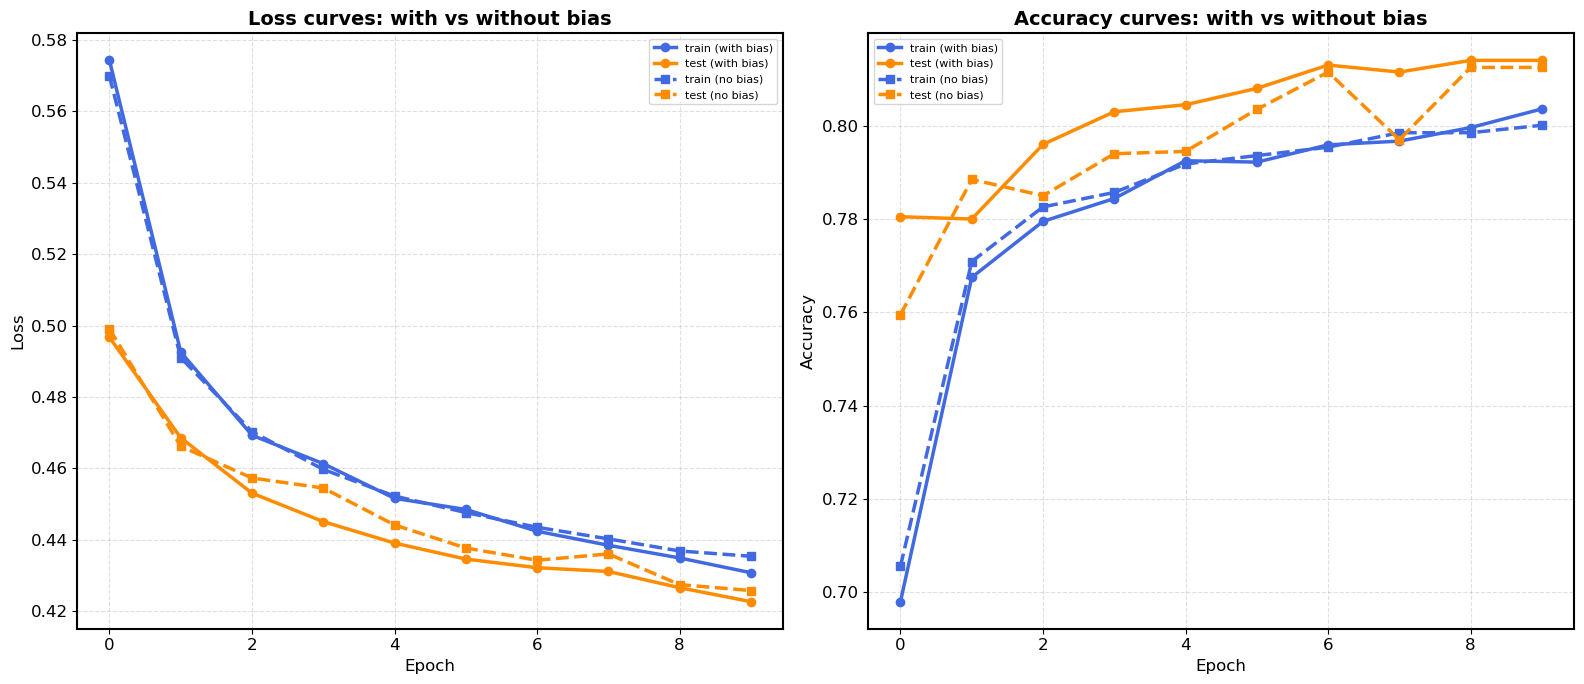

In [34]:
# Note on Parameters, Settings. Refer to the archived source for the detailed original comment.
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(16, 7))

# Note on Define. Refer to the archived source for the detailed original comment.
# Note on Training, Testing. Refer to the archived source for the detailed original comment.
# 有偏置用实线 (Solid: '-')，无偏置用虚线 (Dashed: '--')
color_train = 'RoyalBlue'
color_test = 'DarkOrange'
linewidth_solid = 2.5
linewidth_dashed = 2.5
marker_size = 6

# ===== Loss 对比图 =====
# 有偏置（实线）
ax_loss.plot(train_losses, marker='o', linestyle='-', label='train (with bias)', 
             color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_loss.plot(test_losses, marker='o', linestyle='-', label='test (with bias)', 
             color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无偏置（虚线，加粗）
ax_loss.plot(train_losses_nobias, marker='s', linestyle='--', label='train (no bias)', 
             color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_loss.plot(test_losses_nobias, marker='s', linestyle='--', label='test (no bias)', 
             color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_loss.set_title('Loss curves: with vs without bias', fontsize=14, fontweight='bold')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('Loss')
ax_loss.legend(fontsize=8)
ax_loss.grid(True, linestyle='--', alpha=0.4) # 网格淡一点

# ===== Accuracy 对比图 =====
# 有偏置（实线）
ax_acc.plot(train_accuracies, marker='o', linestyle='-', label='train (with bias)', 
            color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_acc.plot(test_accuracies, marker='o', linestyle='-', label='test (with bias)', 
            color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无偏置（虚线）
ax_acc.plot(train_accuracies_nobias, marker='s', linestyle='--', label='train (no bias)', 
            color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_acc.plot(test_accuracies_nobias, marker='s', linestyle='--', label='test (no bias)', 
            color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_acc.set_title('Accuracy curves: with vs without bias', fontsize=14, fontweight='bold')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy')
ax_acc.legend(fontsize=8)
ax_acc.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Analysis / Model / Training

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


## 4. Momentum or not

In [13]:
np.random.seed(42)   # 固定种子

train_losses_nomomentum, test_losses_nomomentum, train_accuracies_nomomentum, test_accuracies_nomomentum = train_logistic(
    train_data, train_labels, test_data, test_labels,
    use_momentum=False
)

loss 0.648 acc 0.580: 100%|█████████████████| 100/100 [00:00<00:00, 1141.99it/s]


  - test acc: 0.704


loss 0.583 acc 0.770: 100%|█████████████████| 100/100 [00:00<00:00, 1365.22it/s]


  - test acc: 0.720


loss 0.568 acc 0.750: 100%|█████████████████| 100/100 [00:00<00:00, 1385.77it/s]


  - test acc: 0.769


... (10 outputs left out)

loss 0.465 acc 0.820: 100%|█████████████████| 100/100 [00:00<00:00, 1470.85it/s]


  - test acc: 0.782


loss 0.490 acc 0.790: 100%|█████████████████| 100/100 [00:00<00:00, 1488.70it/s]


  - test acc: 0.783


In [14]:
 train_accuracies_nomomentum

[np.float64(0.5843),
 np.float64(0.7152000000000001),
 np.float64(0.7384000000000001),
 np.float64(0.7529),
 np.float64(0.7559000000000001),
 np.float64(0.7601),
 np.float64(0.7638999999999999),
 np.float64(0.765),
 np.float64(0.7682000000000001),
 np.float64(0.7686000000000003)]

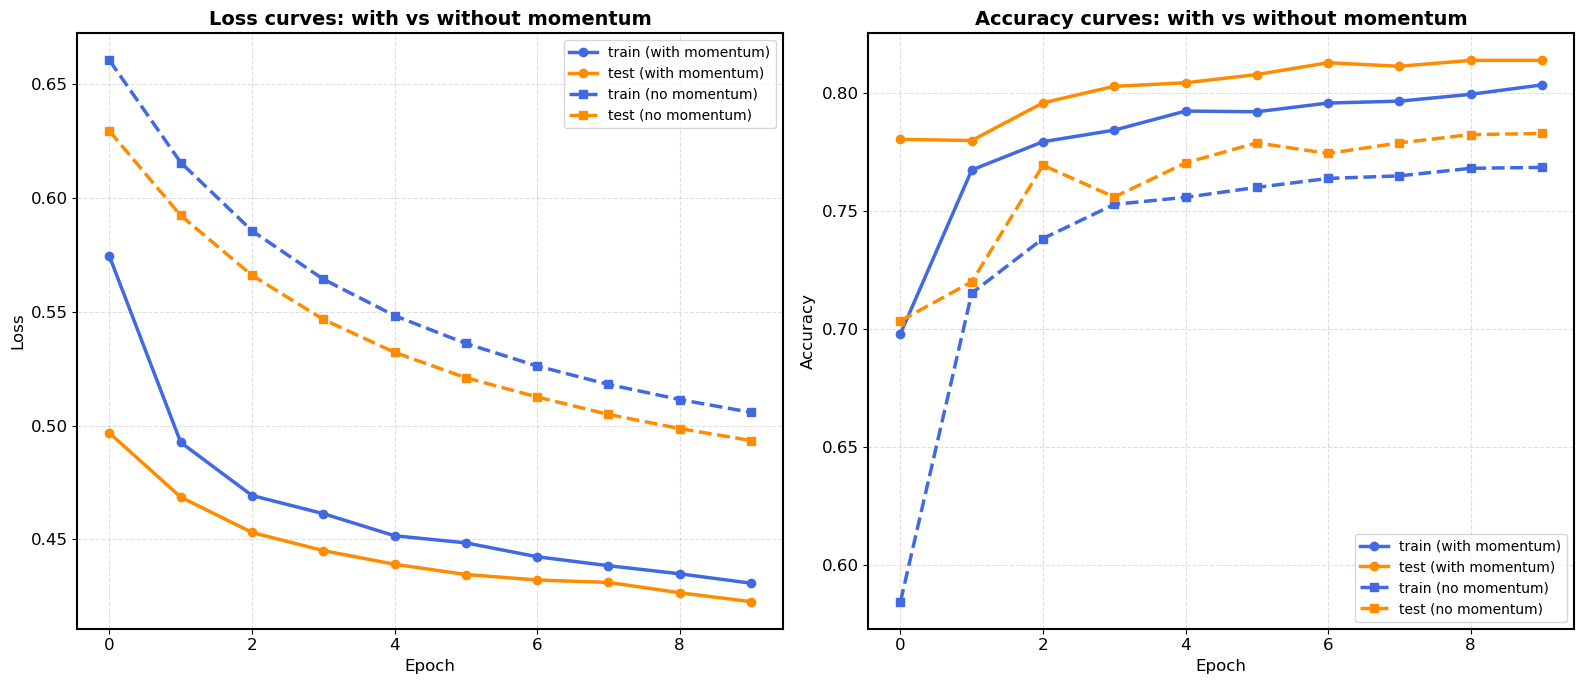

In [37]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(16, 7))

# ===== Loss 对比图 =====
# 有momentums（实线）
ax_loss.plot(train_losses, marker='o', linestyle='-', label='train (with momentum)', 
             color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_loss.plot(test_losses, marker='o', linestyle='-', label='test (with momentum)', 
             color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无momentums（虚线，加粗）
ax_loss.plot(train_losses_nomomentum, marker='s', linestyle='--', label='train (no momentum)', 
             color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_loss.plot(test_losses_nomomentum, marker='s', linestyle='--', label='test (no momentum)', 
             color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_loss.set_title('Loss curves: with vs without momentum', fontsize=14, fontweight='bold')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('Loss')
ax_loss.legend(fontsize=10)
ax_loss.grid(True, linestyle='--', alpha=0.4) # 网格淡一点

# ===== Accuracy 对比图 =====
# 有偏置（实线）
ax_acc.plot(train_accuracies, marker='o', linestyle='-', label='train (with momentum)', 
            color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_acc.plot(test_accuracies, marker='o', linestyle='-', label='test (with momentum)', 
            color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无偏置（虚线）
ax_acc.plot(train_accuracies_nomomentum, marker='s', linestyle='--', label='train (no momentum)', 
            color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_acc.plot(test_accuracies_nomomentum, marker='s', linestyle='--', label='test (no momentum)', 
            color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_acc.set_title('Accuracy curves: with vs without momentum', fontsize=14, fontweight='bold')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy')
ax_acc.legend(fontsize=10)
ax_acc.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Analysis / Model / Testing

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.
